In [1]:
import numpy as np
import matplotlib.pyplot as plt

/tmp/ipykernel_2297/4008340340.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


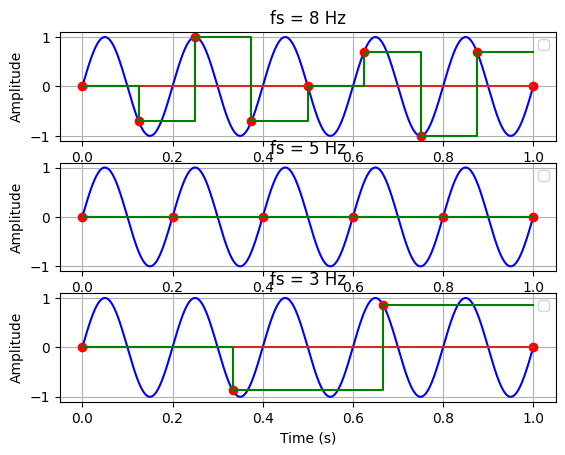

In [5]:
#Task 1

t_fine = np.linspace(0, 1, 10000)
x_analog = np.sin(2 * np.pi * 5 * t_fine)

fs_values = [8, 5, 3]


for idx, fs in enumerate(fs_values):
    Ts = 1 / fs
    n = np.arange(0, 1 + Ts, Ts)

    x_sampled = np.sin(2 * np.pi * 5 * n)

    t_zoh = []
    x_zoh = []
    for i in range(len(n) - 1):
        t_zoh.append(n[i])
        x_zoh.append(x_sampled[i])
        t_zoh.append(n[i+1])
        x_zoh.append(x_sampled[i])

    plt.subplot(3, 1, idx + 1)
    plt.plot(t_fine, x_analog, 'b-')
    plt.stem(n, x_sampled, 'r-')
    plt.plot(t_zoh, x_zoh, 'g-')
    plt.title(f'fs = {fs} Hz')
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.grid()

plt.show()

Original signal x[n] = [ 3  1 -2  4  2]
n indices: [0 1 2 3 4]


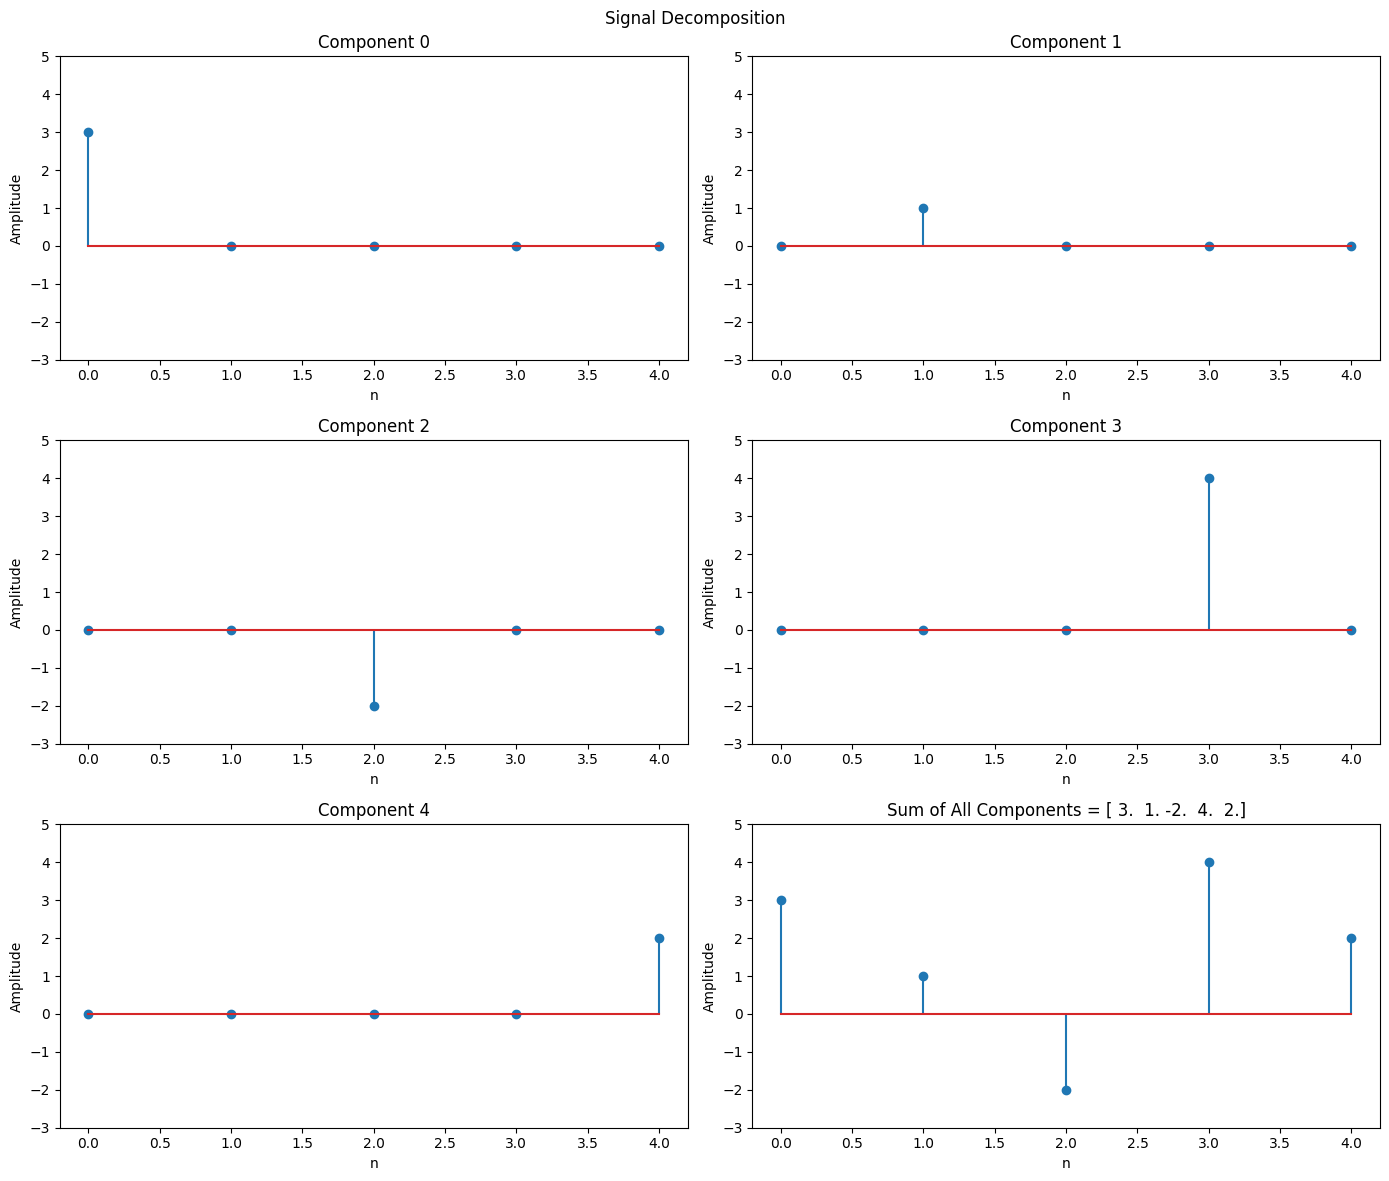

In [18]:
#Task 2
x_n = np.array([3, 1, -2, 4, 2])
n_indices = np.arange(len(x_n))
reconstructed = np.zeros(len(x_n))

print(f"Original signal x[n] = {x_n}")
print(f"n indices: {n_indices}")

plt.figure(figsize=(14, 12))

for k in range(len(x_n)):
    component = np.zeros(len(x_n))
    component[k] = x_n[k]
    reconstructed += component

    plt.subplot(3, 2, k+1)
    plt.stem(n_indices, component)
    plt.title(f'Component {k}')
    plt.xlabel('n')
    plt.ylabel('Amplitude')
    plt.ylim(-3, 5)


plt.subplot(3, 2, 6)
plt.stem(n_indices, reconstructed)
plt.title(f'Sum of All Components = {reconstructed}')
plt.xlabel('n')
plt.ylabel('Amplitude')
plt.ylim(-3, 5)

plt.suptitle('Signal Decomposition')
plt.tight_layout()
plt.show()


Even part x_e[n]: [2.5 2.  1.5 1.  1.  1.  1.5 2.  2.5]
Odd part x_o[n]:  [-2.5 -2.  -1.5 -1.   0.   1.   1.5  2.   2.5]

x_e + x_o = [0. 0. 0. 0. 1. 2. 3. 4. 5.]


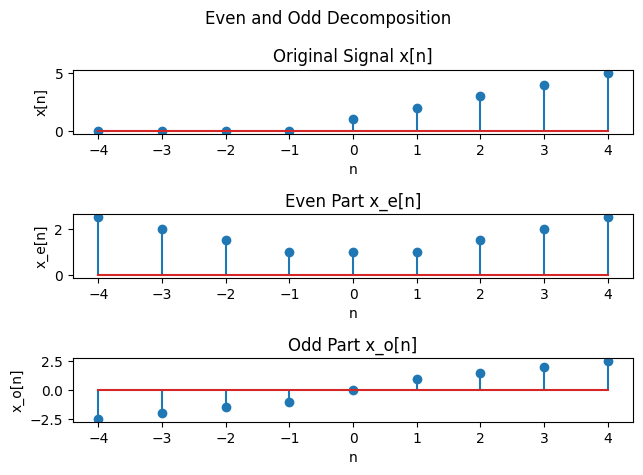

In [27]:
#Task 3
x = np.array([1, 2, 3, 4, 5])
n = np.arange(len(x))

n_full = np.arange(-4, 5)
x_full = np.zeros(len(n_full))

for i, ni in enumerate(n_full):
    if ni >= 0 and ni < len(x):
        x_full[i] = x[ni]

x_folded = x_full[::-1]

x_even = (x_full + x_folded) / 2
x_odd = (x_full - x_folded) / 2

print(f"\nEven part x_e[n]: {x_even}")
print(f"Odd part x_o[n]:  {x_odd}")

x_reconstructed = x_even + x_odd
print(f"\nx_e + x_o = {x_reconstructed}")

plt.subplot(3, 1, 1)
plt.stem(n_full, x_full)
plt.title('Original Signal x[n]')
plt.xlabel('n')
plt.ylabel('x[n]')

plt.subplot(3, 1, 2)
plt.stem(n_full, x_even)
plt.title('Even Part x_e[n]')
plt.xlabel('n')
plt.ylabel('x_e[n]')

plt.subplot(3, 1, 3)
plt.stem(n_full, x_odd)
plt.title('Odd Part x_o[n]')
plt.xlabel('n')
plt.ylabel('x_o[n]')

plt.suptitle('Even and Odd Decomposition')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2297/1873740761.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


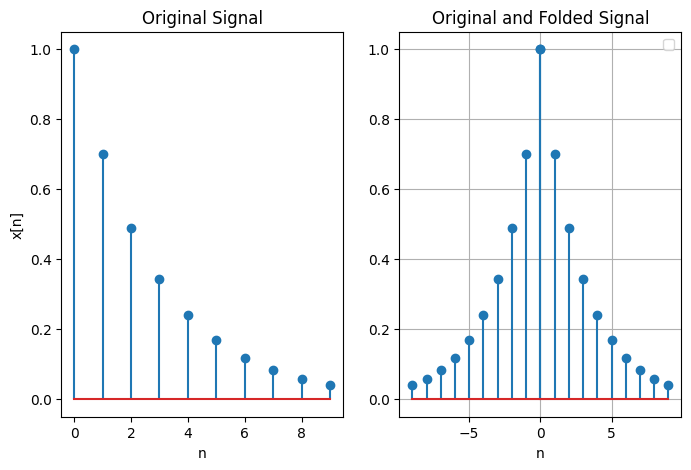

In [41]:
#task4

n = np.arange(0, 10)
x = (0.7) ** n

y = x[::-1]
n_fold = -n[::-1]


plt.figure(figsize=(8,5))

plt.subplot(1, 2, 1)
plt.stem(n, x)
plt.title('Original Signal')
plt.xlabel('n')
plt.ylabel('x[n]')


plt.subplot(1, 2, 2)
plt.stem(n, x)
plt.stem(n_fold, y)

plt.title("Original and Folded Signal")
plt.xlabel("n")
plt.grid()
plt.legend()
plt.show()

x[-n+2] = [1. 2. 3. 4. 3. 2. 1.]
Expected: [1, 2, 3, 4, 3, 2, 1]


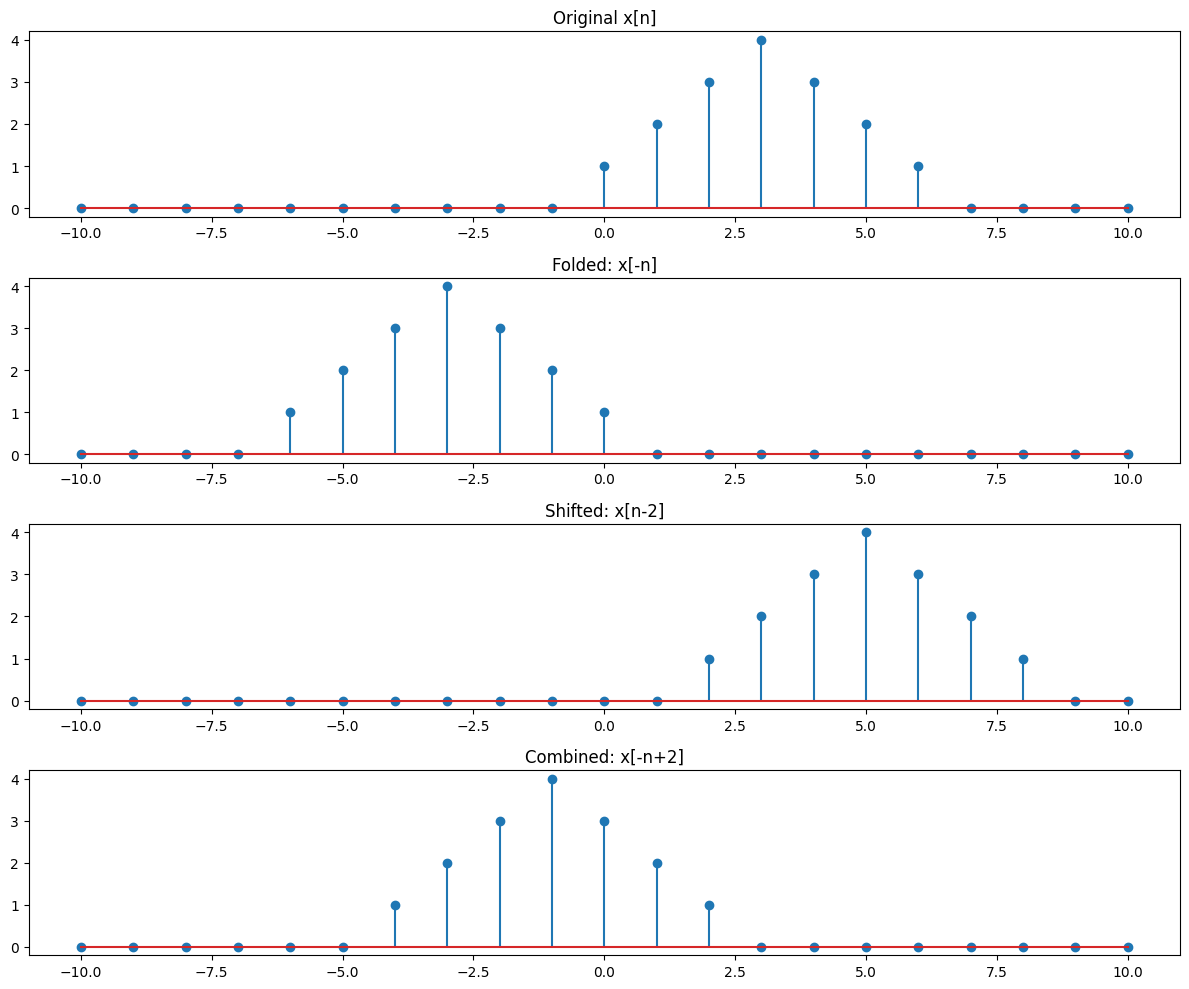

In [30]:
#Task 5
x = np.array([1, 2, 3, 4, 3, 2, 1])
n = np.arange(-10, 11)

x_extended = np.zeros(len(n))
for i, val in enumerate(n):
    if 0 <= val < len(x):
        x_extended[i] = x[val]

x_folded = np.zeros(len(n))
for i, val in enumerate(n):
    idx = -val
    if 0 <= idx < len(x):
        x_folded[i] = x[idx]

x_shifted = np.zeros(len(n))
for i, val in enumerate(n):
    idx = val - 2
    if 0 <= idx < len(x):
        x_shifted[i] = x[idx]

x_combined = np.zeros(len(n))
for i, val in enumerate(n):
    idx = -val + 2
    if 0 <= idx < len(x):
        x_combined[i] = x[idx]

print(f"x[-n+2] = {x_combined[n >= -4][:7]}")
print(f"Expected: [1, 2, 3, 4, 3, 2, 1]")

plt.figure(figsize=(12, 10))

plt.subplot(4,1,1)
plt.stem(n, x_extended)
plt.title('Original x[n]')

plt.subplot(4,1,2)
plt.stem(n, x_folded)
plt.title('Folded: x[-n]')

plt.subplot(4,1,3)
plt.stem(n, x_shifted)
plt.title('Shifted: x[n-2]')

plt.subplot(4,1,4)
plt.stem(n, x_combined)
plt.title('Combined: x[-n+2]')

plt.tight_layout()
plt.show()

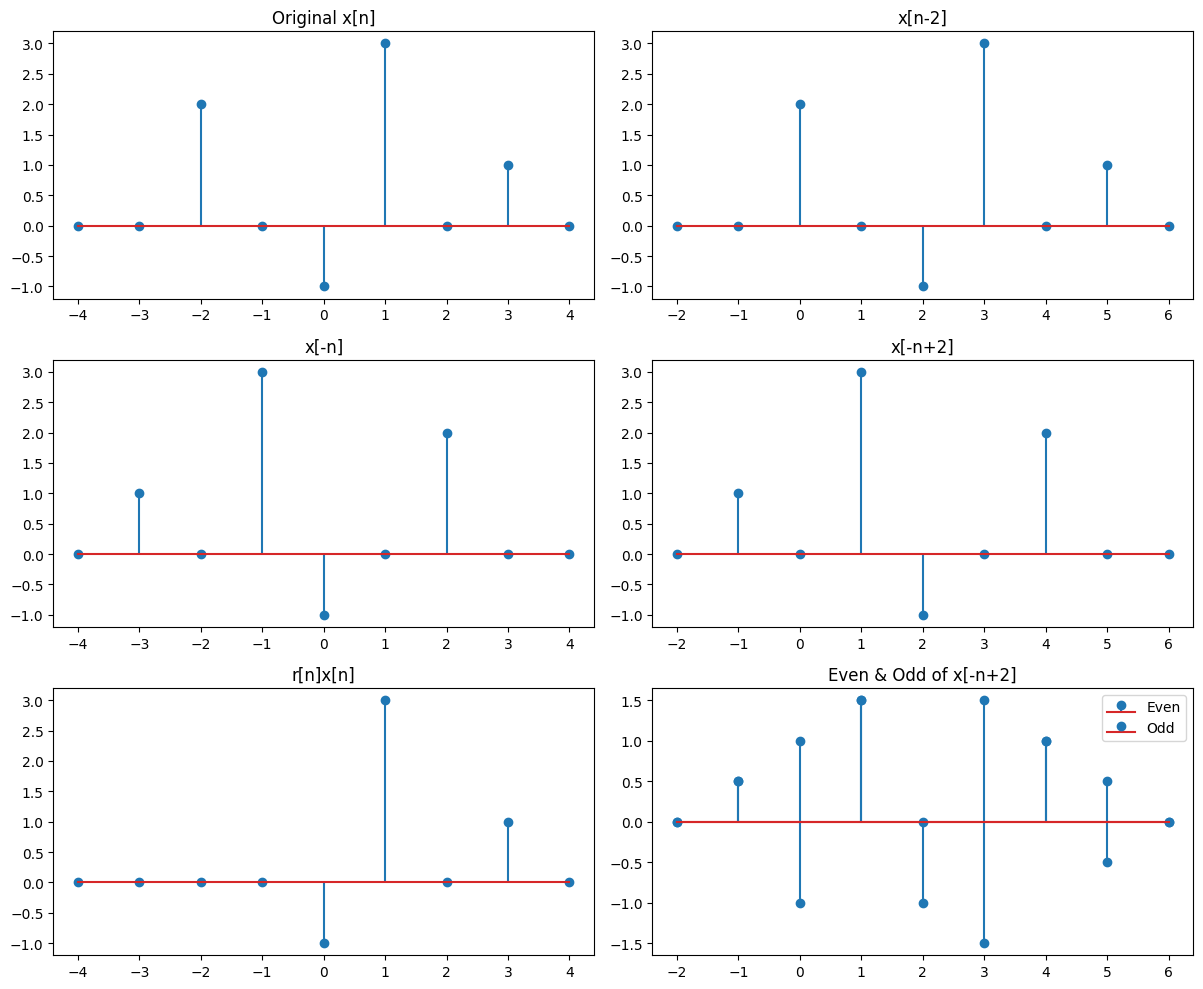

In [46]:
#task6
import numpy as np
import matplotlib.pyplot as plt



n = np.arange(-4, 5)
x = np.zeros(len(n))


x[n == -2] = 2
x[n == 0] = -1
x[n == 1] = 3
x[n == 3] = 1


# 2. x[n-2] (shift right)

n_shift = n + 2
x_shift = x


# 3. x[-n] (fold)

n_fold = -n[::-1]
x_fold = x[::-1]


# 4. x[-n+2] (fold + shift)

n_combined = n_fold + 2
x_combined = x_fold


# 5. r[n]x[n] (u[n] * x[n])

u = np.where(n >= 0, 1, 0)
x_r = x * u


# 6. Even-Odd decomposition of x[-n+2]


x_neg = x_combined[::-1]

xe = (x_combined + x_neg) / 2
xo = (x_combined - x_neg) / 2


# 7. Plot all

plt.figure(figsize=(12,10))

plt.subplot(3, 2, 1)
plt.stem(n, x)
plt.title("Original x[n]")

plt.subplot(3, 2, 2)
plt.stem(n_shift, x_shift)
plt.title("x[n-2]")

plt.subplot(3, 2, 3)
plt.stem(n_fold, x_fold)
plt.title("x[-n]")

plt.subplot(3, 2, 4)
plt.stem(n_combined, x_combined)
plt.title("x[-n+2]")

plt.subplot(3, 2, 5)
plt.stem(n, x_r)
plt.title("r[n]x[n]")

plt.subplot(3, 2, 6)
plt.stem(n_combined, xe, label="Even")
plt.stem(n_combined, xo, label="Odd")
plt.title("Even & Odd of x[-n+2]")
plt.legend()

plt.tight_layout()
plt.show()

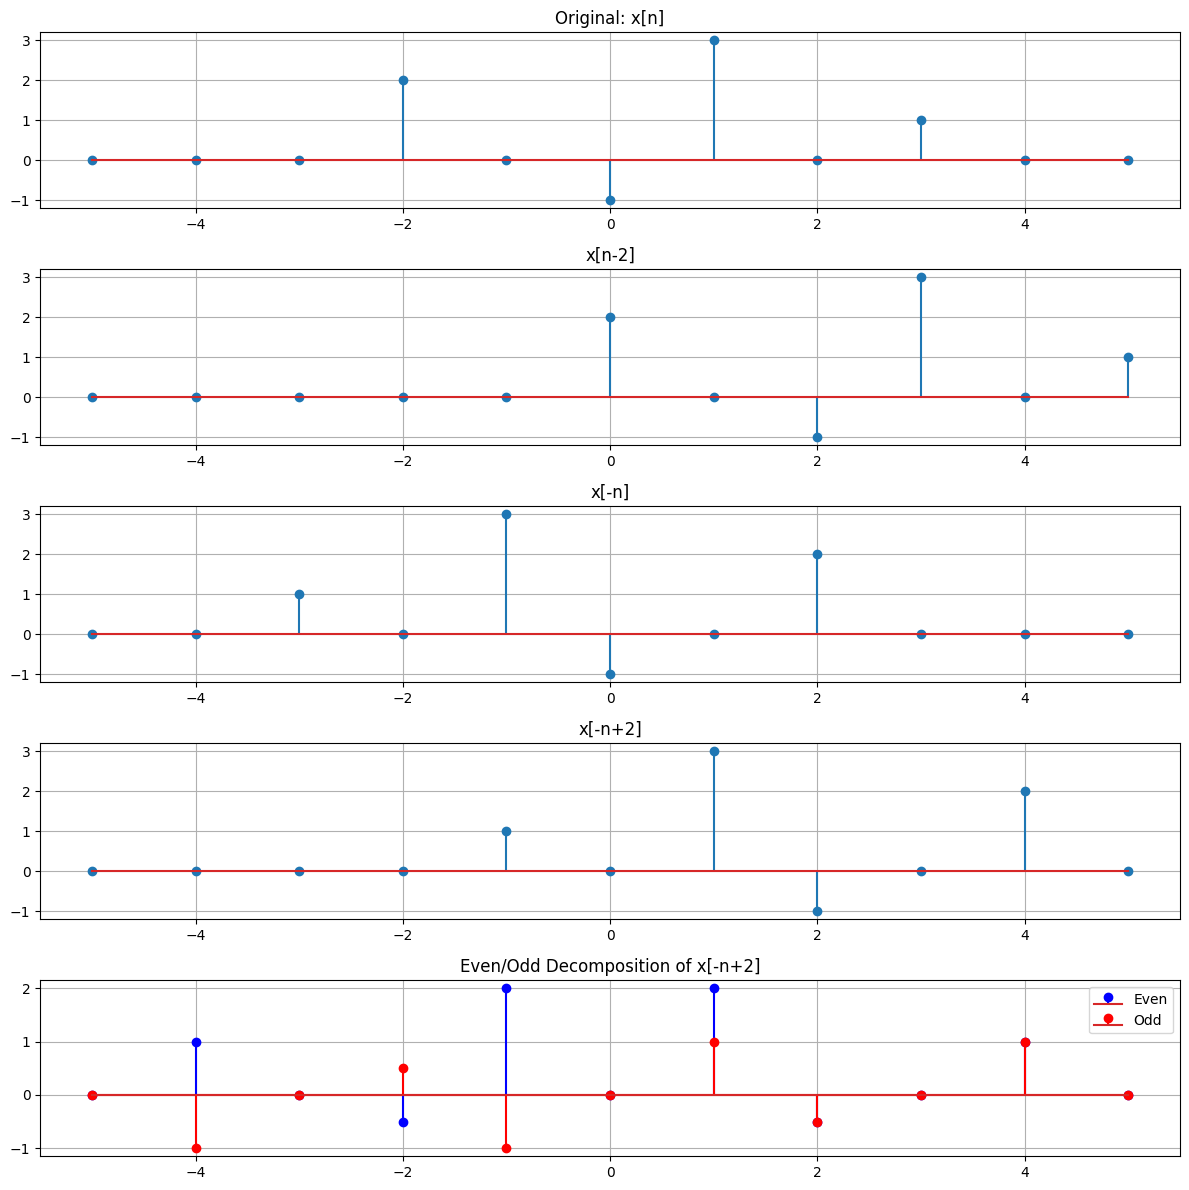

In [42]:
import numpy as np
import matplotlib.pyplot as plt

# Define original signal x[n] from -5 to 5
n = np.arange(-5, 6)
x = np.zeros(len(n))

x[n == -2] = 2   # 2δ[n+2]
x[n == 0] = -1   # -δ[n]
x[n == 1] = 3    # 3δ[n-1]
x[n == 3] = 1    # δ[n-3]

# ============================================
# YOUR SIMPLE APPROACH for x[n-2]
# ============================================
x_shift = np.zeros(len(n))

for i, val in enumerate(n):
    # For output index val, we need original index (val - 2)
    idx = val - 2

    # Check if idx is within the original n range (-5 to 5)
    if -5 <= idx <= 5:
        # Find the position in the array
        pos = np.where(n == idx)[0]
        if len(pos) > 0:
            x_shift[i] = x[pos[0]]
    # Otherwise, value stays 0

# ============================================
# YOUR SIMPLE APPROACH for x[-n] (folding)
# ============================================
x_fold = np.zeros(len(n))

for i, val in enumerate(n):
    # For output index val, we need original index -val
    idx = -val

    # Check if idx is within the original n range (-5 to 5)
    if -5 <= idx <= 5:
        pos = np.where(n == idx)[0]
        if len(pos) > 0:
            x_fold[i] = x[pos[0]]

# ============================================
# YOUR SIMPLE APPROACH for x[-n+2]
# ============================================
x_combined = np.zeros(len(n))

for i, val in enumerate(n):
    # For output index val, we need original index -val + 2
    idx = -val + 2

    if -5 <= idx <= 5:
        pos = np.where(n == idx)[0]
        if len(pos) > 0:
            x_combined[i] = x[pos[0]]

# Plot results
fig, axes = plt.subplots(4, 1, figsize=(10, 10))

axes[0].stem(n, x, basefmt='gray')
axes[0].set_title('Original x[n]')
axes[0].grid(True)

axes[1].stem(n, x_shift, basefmt='gray')
axes[1].set_title('x[n-2] (Your simple method)')
axes[1].grid(True)

axes[2].stem(n, x_fold, basefmt='gray')
axes[2].set_title('x[-n] (Your simple method)')
axes[2].grid(True)

axes[3].stem(n, x_combined, basefmt='gray')
axes[3].set_title('x[-n+2] (Your simple method)')
axes[3].grid(True)

plt.tight_layout()
plt.show()

# Print results
print("Original x[n]:")
for i, val in enumerate(n):
    if x[i] != 0:
        print(f"  x[{val}] = {x[i]}")

print("\nx[n-2]:")
for i, val in enumerate(n):
    if x_shift[i] != 0:
        print(f"  x_shift[{val}] = {x_shift[i]}")

print("\nx[-n]:")
for i, val in enumerate(n):
    if x_fold[i] != 0:
        print(f"  x_fold[{val}] = {x_fold[i]}")

print("\nx[-n+2]:")
for i, val in enumerate(n):
    if x_combined[i] != 0:
        print(f"  x_combined[{val}] = {x_combined[i]}")